## Import torch and cuda

In [3]:
import torch
torch.cuda.is_available()

True

In [4]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


## Imports

In [5]:
from dataclasses import dataclass, field
import pandas as pd
import torch
from typing import Tuple

# for transformation
import torchvision.transforms as T
import torchvision.transforms.functional as F

import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt

import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from sklearn.metrics import roc_auc_score

import time
import matplotlib.pyplot as plt

C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


## Configuration

### These values or parameters are mentioned in paper
- adaptation_ratio = 20%
- Corruptions: gaussian noise, defocus blur, brightness, contrast, at severity 5
- memory_bank: size N x M
- Updated params: BatchNorm affine only
- Target augmentation
- ReallAD input size = 1024


### These values are outside and will be tunable
- WideResNet50 and layer2/layer3 features (from the PatchCore paper)
- 256 resize and 224 crop
- ImageNet mean/std
- Core-set ratio (e.g., 1-10%)
- Learning rate, epochs, batch size
- Sinkhorn ε and number of iterations
= num_workers and seed

In [6]:
@dataclass
class Configuration:

    source = "./data/bottle/train"
    target = "./data/bottle/test"

    # image size according to research paper given - only ReallAD needs 1024 x 1024
    # initial step only considering MVTecAD Dataset


    image_size: int = 256
    batch_size_source: int = 16 # not mentioned in paper taken genral value

    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)

    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")


    coreset_ratio: float = 0.2 # memory bank settings (core-set size N_M: no value in paper; ratio is a tunable choice)


    adaption_ratio: float = 0.20 # fraction of target data used for adaptation , value mentioned in paper.
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4 # learning rate
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50

    # corruption settings
    corruptions: Tuple[str, ...] = ("gaussian_noise", "defocus_blur", "brightness", "contrast")
    severity: int=5

    # Misc
    seed: int=42
    num_workers: int=0

    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024

    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42

CFG = Configuration()


## Dataset & Image transformation

In [7]:
def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image,image_size):
    return F.resize(image, [image_size,image_size], interpolation=T.InterpolationMode.BILINEAR)


def center_crop(image, image_size):
    return F.center_crop(image, [image_size,image_size])


def convert_to_tensor(image):
    return F.to_tensor(image)


def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)
    tensor = convert_to_tensor(image)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)

### Masking ground truth

In [8]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

# T.Interpolation is also possible try when low performance

In [9]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)



In [10]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)             # reproducible noise per image
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))

In [11]:
class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.CFG=CFG
        self.corruption=corruption
        test_dir=os.path.join(root, category,"test")
        gt_dir=os.path.join(root, category, "ground_truth")
        self.items=[]
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p,0,None))
                else:
                    stem=os.path.splitext(os.path.basename(p))[0]
                    mp=os.path.join(gt_dir, defect, stem+"_mask.png")
                    self.items.append((p,1,mp))
        self.labels = [it[1] for it in self.items]
    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, mpath = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        x=base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

In [12]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())

In [13]:
class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]       # labels/masks are NOT used (unlabeled target data)
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [14]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                               num_workers=CFG.num_workers)
    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, drop_last=True)
    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    return source_loader, adapt_loader, test_loader

## Feature Extraction and Memory Bank

In [15]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():          # freeze all for now (BN affine unfrozen later in adaptation)
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)                  # (B, 512, 28, 28) for 224 crop
        f3 = self.layer3(f2)                 # (B, 1024, 14, 14)

        # local neighborhood aggregation
        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)

        # align spatial size, then merge along channels
        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], dim=1)       # (B, 1536, 28, 28)

        # patches: (B, N_p, 1536) -> reduce channels to fixed dim D
        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)   # (B, N_p, D)

# ---- 3.2 Extract all source patch features ----
@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:                         # SourceDataset returns only the image
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)      # (N_img, N_p, D)
    return feats.reshape(-1, feats.shape[-1])  # (N_img * N_p, D)

# ---- 3.3 Greedy k-center core-set (Eq. 1 objective; algorithm from PatchCore) ----
@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj                # cheap distances in low-dim space
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)            # farthest from the chosen set
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]                # (N_M, D) in original feature space

# ---- 3.4 Build memory bank ----
def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank                              # fixed, never updated during adaptation

# ---- 3.5 Anomaly scoring (Eq. 2) ----
@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))                          # (B, N_p, D)
        for i in range(feats.shape[0]):                      # per image to save memory
            d = torch.cdist(feats[i], memory_bank)           # (N_p, N_M)
            patch_scores = d.min(dim=1).values               # min over memory bank
            scores.append(patch_scores.max().item())         # max over patches
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)

# ---- 3.6 Run + sanity check on CLEAN data ----
model = FeatureExtractor(CFG).to(CFG.device)

source_ds = SourceDataset(CFG, CFG.root, CFG.category)
source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                           num_workers=CFG.num_workers)
memory_bank = build_memory_bank(model, source_loader, CFG)

clean_ds = TestDataset(CFG.root, CFG.category, CFG, corruption=None)
clean_loader = DataLoader(clean_ds, batch_size=CFG.batch_size, shuffle=False,
                          num_workers=CFG.num_workers)
s, y = score_images(model, clean_loader, memory_bank, CFG.device)
print("Clean image AUROC:", roc_auc_score(y, s))

Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


## Base evaluation on corrupted data

In [16]:
# ---- Step 4: baseline "w/o adapt" evaluation ----
def make_test_split(corruption, CFG):
    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    tr, te = split_target(ds, CFG)       # same seed + same labels -> identical indices every time
    return tr, te

def make_loader(subset, CFG):
    return DataLoader(subset, batch_size=CFG.batch_size, shuffle=False,
                      num_workers=CFG.num_workers)

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}

# 5. Clean AUROC on the same 80% test split
_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")

# 1-4. Corrupted test sets (severity 5), score only the 80% split
for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")

# 6. Table
print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.7953
defocus_blur: 1.0000
brightness: 1.0000
contrast: 0.7132
clean             1.0000
gaussian_noise    0.7953
defocus_blur      1.0000
brightness        1.0000
contrast          0.7132
Name: w/o adapt AUROC, dtype: float64


## Sinkhorn and discretization functions

In [17]:
# ---- Add to Configuration ----
#     max_adapt_patches: int = 2048   # outside paper: patches sampled per batch

# ---- 5.1 Cost matrix (paper Eq. 4: Euclidean distance) ----
def cost_matrix(z, bank):
    return torch.cdist(z, bank)                      # (N_tp, N_M), keeps gradient w.r.t. z

# ---- 5.2 Sample target patches from a batch (outside paper) ----
def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])           # (B*N_p, D)
    if z.shape[0] > max_patches:
        idx = torch.randperm(z.shape[0], device=z.device)[:max_patches]
        z = z[idx]
    return z

# ---- 5.3 Sinkhorn in log domain (paper Eq. 5; log-domain is outside paper) ----
@torch.no_grad()
def sinkhorn(C, eps, n_iters):
    N, M = C.shape
    Cn = C / C.mean()                                # normalize so exp(-C/eps) is stable
    logK = -Cn / eps
    log_a = -torch.log(torch.tensor(float(N), device=C.device))   # row marginal 1/N_tp
    log_b = -torch.log(torch.tensor(float(M), device=C.device))   # col marginal 1/N_M
    log_u = torch.zeros(N, device=C.device)
    log_v = torch.zeros(M, device=C.device)
    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(logK + log_v[None, :], dim=1)
        log_v = log_b - torch.logsumexp(logK + log_u[:, None], dim=0)
    return torch.exp(logK + log_u[:, None] + log_v[None, :])      # gamma*, (N_tp, N_M)

# ---- 5.4 Discretization (paper Eq. 6) ----
@torch.no_grad()
def discretize(gamma):
    N, M = gamma.shape
    pi = torch.zeros(N, M, dtype=torch.bool, device=gamma.device)
    pi[torch.arange(N, device=gamma.device), gamma.argmax(dim=1)] = True   # j = argmax_j gamma_ij
    pi[gamma.argmax(dim=0), torch.arange(M, device=gamma.device)] = True   # i = argmax_i gamma_ij
    return pi

# ---- 5.5 Robust Sinkhorn alignment loss (paper Eq. 6) ----
def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)   # (N_tp, D), carries gradient
    C = cost_matrix(z, bank)                           # un-normalized Euclidean cost
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)   # fixed pseudo-labels
    pi = discretize(gamma)
    loss = C[pi].sum() / z.shape[0]                    # normalize by N_tp (outside paper)
    if return_stats:
        return loss, gamma, pi
    return loss

# ---- 5.6 Sanity check on one corrupted adaptation batch ----
tr, _ = make_test_split("gaussian_noise", CFG)
batch = next(iter(DataLoader(AdaptDataset(tr), batch_size=CFG.batch_size, shuffle=True)))

with torch.no_grad():
    feats = model(batch.to(CFG.device))
loss, gamma, pi = robust_sinkhorn_loss(feats, memory_bank, CFG, return_stats=True)

N, M = gamma.shape
print("loss:", loss.item())
print("row sums vs 1/N_tp:", gamma.sum(1).mean().item(), 1 / N)
print("col sums vs 1/N_M :", gamma.sum(0).mean().item(), 1 / M)
print("nonzeros in pi:", pi.sum().item(), "of", N * M)

loss: 56.1478157043457
row sums vs 1/N_tp: 0.0009765629656612873 0.0009765625
col sums vs 1/N_M : 3.0514798709191382e-05 3.0514784413048123e-05
nonzeros in pi: 33278 of 33557504


## Adaptation loop, batchNorm-only updates

In [18]:
# ---- Add to Configuration ----
#     max_adapt_patches: int = 2048   # outside paper: patches sampled per batch
#     adapt_batch_size: int = 8       # outside paper: smaller than 16 to fit backprop on 6 GB GPU

# ---- 6.1 Fresh model with only BatchNorm affine params trainable (paper: BN affine only) ----
def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)         # loads the same pretrained weights, all frozen
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):         # affine params only
                p.requires_grad = True
                bn_params.append(p)
    m.eval()                                         # keeps BN running stats fixed (outside paper)
    return m, bn_params

# ---- 6.2 Adaptation loop (paper Algorithm 1; optimizer/lr are outside paper) ----
def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=True),   # random 90-degree rotations
                        batch_size=CFG.adapt_batch_size, shuffle=True,
                        num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()                                 # eval mode: only affine params change
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))          # NO torch.no_grad(): loss needs gradients
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history

# ---- 6.3 Run one corruption: adapt on 20%, evaluate on the same 80% as Step 4 ----
def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed); random.seed(CFG.seed); np.random.seed(CFG.seed)
    target_tr, target_te = make_test_split(corruption, CFG)
    model_a, bn_params = make_adapt_model(CFG)       # fresh model per corruption
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    return auroc, history

# ---- 6.4 Test on one corruption first ----
auroc, hist = run_roda("gaussian_noise", memory_bank, CFG)
print(f"gaussian_noise  w/o adapt: {baseline_results['gaussian_noise']:.4f}  RoDA: {auroc:.4f}")

  epoch 1/10  loss 55.8129
  epoch 2/10  loss 54.8227
  epoch 3/10  loss 53.5901
  epoch 4/10  loss 53.3086
  epoch 5/10  loss 52.2126
  epoch 6/10  loss 51.2922
  epoch 7/10  loss 50.2338
  epoch 8/10  loss 49.6142
  epoch 9/10  loss 48.8424
  epoch 10/10  loss 47.8908
gaussian_noise  w/o adapt: 0.7953  RoDA: 0.8554


## Run RoDA on all corruptions and compare

[gaussian_noise] seed 0
  epoch 1/10  loss 56.7640
  epoch 2/10  loss 55.2412
  epoch 3/10  loss 53.9406
  epoch 4/10  loss 53.2699
  epoch 5/10  loss 52.1553
  epoch 6/10  loss 51.1664
  epoch 7/10  loss 49.7278
  epoch 8/10  loss 49.2041
  epoch 9/10  loss 49.1136
  epoch 10/10  loss 48.1146
  -> AUROC 0.8542
[gaussian_noise] seed 1
  epoch 1/10  loss 55.9949
  epoch 2/10  loss 54.9071
  epoch 3/10  loss 53.9801
  epoch 4/10  loss 53.0523
  epoch 5/10  loss 52.2386
  epoch 6/10  loss 51.4549
  epoch 7/10  loss 49.9321
  epoch 8/10  loss 49.6986
  epoch 9/10  loss 48.7052
  epoch 10/10  loss 48.4704
  -> AUROC 0.8566
[gaussian_noise] seed 2
  epoch 1/10  loss 55.9320
  epoch 2/10  loss 55.5906
  epoch 3/10  loss 54.7581
  epoch 4/10  loss 53.6038
  epoch 5/10  loss 51.9841
  epoch 6/10  loss 50.6070
  epoch 7/10  loss 49.9990
  epoch 8/10  loss 49.5435
  epoch 9/10  loss 48.9108
  epoch 10/10  loss 48.0083
  -> AUROC 0.8554
[gaussian_noise] done in 60s

[defocus_blur] seed 0
  epoch 1

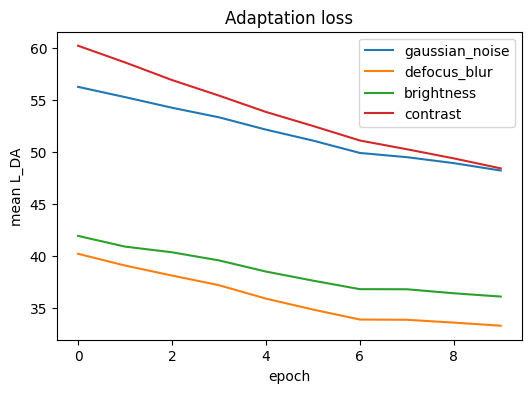

In [19]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0,1,2]

class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return auroc, history

roda_runs = {}      # corruption -> list of AUROCs over seeds
histories = {}      # corruption -> list of loss curves


for c in CFG.corruptions:
    t0 = time.time()
    tr, te = make_test_split(c, CFG)
    tr, te = CachedDataset(tr), CachedDataset(te)
    roda_runs[c], histories[c] = [], []
    for sd in SEEDS:
        print(f"[{c}] seed {sd}")
        a, h = run_roda_seed(tr, te, memory_bank, CFG, sd)
        roda_runs[c].append(a)
        histories[c].append(h)
        print(f"  -> AUROC {a:.4f}")
    print(f"[{c}] done in {time.time()-t0:.0f}s\n")


rows = []
for c in CFG.corruptions:
    m, s = np.mean(roda_runs[c]), np.std(roda_runs[c])
    rows.append({
        "corruption": c,
        "clean": baseline_results["clean"],
        "w/o adapt": baseline_results[c],
        "RoDA mean":m,
        "RoDA std":s,
        "diff":m-baseline_results[c],
    })
results_df = pd.DataFrame(rows).set_index("corruption").round(4)
print(results_df)

plt.figure(figsize=(6,4))
for c in CFG.corruptions:
    plt.plot(np.mean(histories[c], axis=0), label=c)
plt.xlabel("epoch")
plt.ylabel("mean L_DA")
plt.legend()
plt.title("Adaptation loss")
plt.show()

## Abiliations

In [20]:
# ---- Add to Configuration ----
#     assignment: str = "discrete"    # "discrete" or "continuous"
#     aug_mode: str = "augment"       # "none", "copy" or "augment"

# ---- 8.1 Loss with switchable assignment (paper Eq. 5 vs Eq. 6) ----
def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    if CFG.assignment == "continuous":
        loss = (gamma * C).sum()                    # sum of gamma*·C, gamma sums to 1
        pi = None
    else:
        pi = discretize(gamma)
        loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss

# ---- 8.2 Adaptation loop with switchable augmentation ----
def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=(CFG.aug_mode == "augment")),
                        batch_size=CFG.adapt_batch_size, shuffle=True,
                        num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            if CFG.aug_mode == "copy":
                feats = torch.cat([feats, feats], dim=0)   # direct copy, no transform
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
    return history

# ---- 8.3 Run the four configurations ----
ablation_cfgs = {
    "continuous | none":    ("continuous", "none"),
    "discrete | none":      ("discrete",   "none"),
    "discrete | copy":      ("discrete",   "copy"),
    "discrete | augment":   ("discrete",   "augment"),   # full RoDA
}

# Build and cache each corruption's splits once
splits = {}
for c in CFG.corruptions:
    tr, te = make_test_split(c, CFG)
    splits[c] = (CachedDataset(tr), CachedDataset(te))

ablation = {}   # (config name, corruption) -> mean AUROC over seeds
for name, (assign, aug) in ablation_cfgs.items():
    CFG.assignment, CFG.aug_mode = assign, aug
    for c in CFG.corruptions:
        tr, te = splits[c]
        aurocs = []
        for sd in SEEDS:
            a, _ = run_roda_seed(tr, te, memory_bank, CFG, sd)
            aurocs.append(a)
        ablation[(name, c)] = np.mean(aurocs)
        print(f"{name:22s} {c:15s} {ablation[(name, c)]:.4f}")

# restore defaults
CFG.assignment, CFG.aug_mode = "discrete", "augment"

# ---- 8.4 Table (rows = configs, columns = corruptions) ----
abl_df = pd.Series(ablation).unstack()
abl_df.insert(0, "w/o adapt (mean)", np.mean([baseline_results[c] for c in CFG.corruptions]))
abl_df["mean"] = abl_df[list(CFG.corruptions)].mean(axis=1)
print(abl_df.round(4))

continuous | none      gaussian_noise  0.8309
continuous | none      defocus_blur    1.0000
continuous | none      brightness      1.0000
continuous | none      contrast        0.9722
discrete | none        gaussian_noise  0.8664
discrete | none        defocus_blur    1.0000
discrete | none        brightness      1.0000
discrete | none        contrast        0.9547
discrete | copy        gaussian_noise  0.8664
discrete | copy        defocus_blur    1.0000
discrete | copy        brightness      1.0000
discrete | copy        contrast        0.9538
discrete | augment     gaussian_noise  0.8554
discrete | augment     defocus_blur    1.0000
discrete | augment     brightness      1.0000
discrete | augment     contrast        0.9534
                    w/o adapt (mean)  brightness  contrast  defocus_blur  \
continuous | none             0.8771         1.0    0.9722           1.0   
discrete | augment            0.8771         1.0    0.9534           1.0   
discrete | copy               0.8771